In [1]:
!pip install -q fairlearn scikit-learn pandas numpy matplotlib seaborn

Dataset shape: (5000, 11)
   applicant_id gender_group race_group  education_level  years_experience  \
0             1         Male    Group_A                2                11   
1             2       Female    Group_A                2                 5   
2             3       Female    Group_C                2                12   
3             4       Female    Group_A                3                15   
4             5         Male    Group_C                3                12   

   skills_score  assessment_score  qualification_score  objectively_qualified  \
0     60.362985         90.779653            69.785659                      1   
1     58.935363         83.502363            55.609432                      0   
2     89.028150         70.965094            73.998311                      1   
3     81.471257         68.475130            82.486597                      1   
4     93.323009         74.153140            80.869037                      1   

   baseline_decisi

,Model,Accuracy,Precision,Recall,F1 Score,Gender DP Difference,Gender DP Ratio
0,Baseline,0.957,0.9503,0.9754,0.9626,0.0316,0.9471
1,Biased,0.745,1.0000,0.5511,0.7106,0.2389,0.4276
2,Mitigated,0.745,1.0000,0.5511,0.7106,0.0357,0.8914



GENDER FAIRNESS RESULTS


,Model,Gender,Selection Rate,True Positive Rate,False Positive Rate
0,Baseline,Female,0.5652,0.9673,0.0521
1,Baseline,Male,0.5968,0.9814,0.0792
2,Biased,Female,0.1785,0.3184,0.0000
3,Biased,Male,0.4174,0.7276,0.0000
4,Mitigated,Female,0.2929,0.5224,0.0000
5,Mitigated,Male,0.3286,0.5728,0.0000



INTERSECTIONAL AUDIT


,applicants,qualified,baseline_selection,biased_selection,mitigated_selection
intersection_group,,,,,
Female_Group_A,230,128,0.5565,0.1913,0.2739
Female_Group_B,129,73,0.5814,0.1860,0.3411
Female_Group_C,78,44,0.5641,0.1282,0.2692
Male_Group_A,293,163,0.5734,0.3993,0.3140
Male_Group_B,175,110,0.6457,0.4571,0.3429
Male_Group_C,95,50,0.5789,0.4000,0.3474



FALSE NEGATIVE RATE AUDIT


,Intersection,Model,False Negative Rate,Applicants
0,Female_Group_A,Baseline,0.0469,230
1,Female_Group_A,Biased,0.6562,230
2,Female_Group_A,Mitigated,0.5078,230
3,Female_Group_B,Baseline,0.0137,129
4,Female_Group_B,Biased,0.6712,129
5,Female_Group_B,Mitigated,0.3973,129
6,Female_Group_C,Baseline,0.0227,78
7,Female_Group_C,Biased,0.7727,78
8,Female_Group_C,Mitigated,0.5227,78
9,Male_Group_A,Baseline,0.0184,293


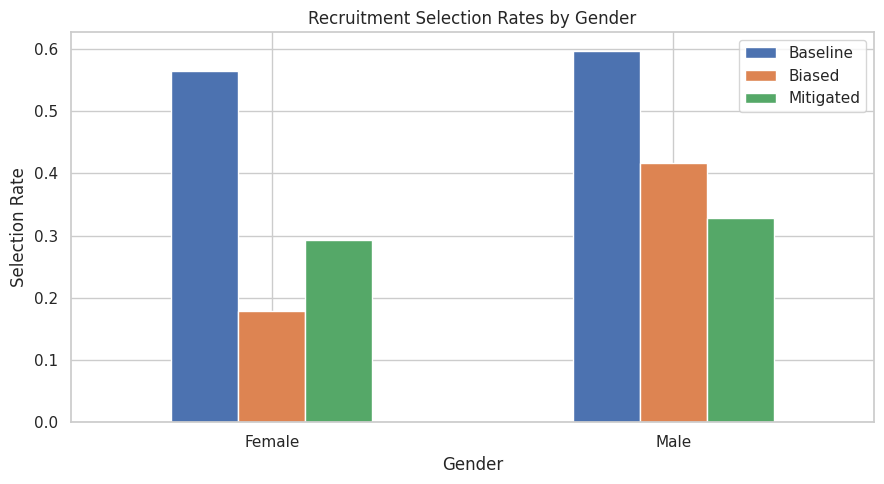

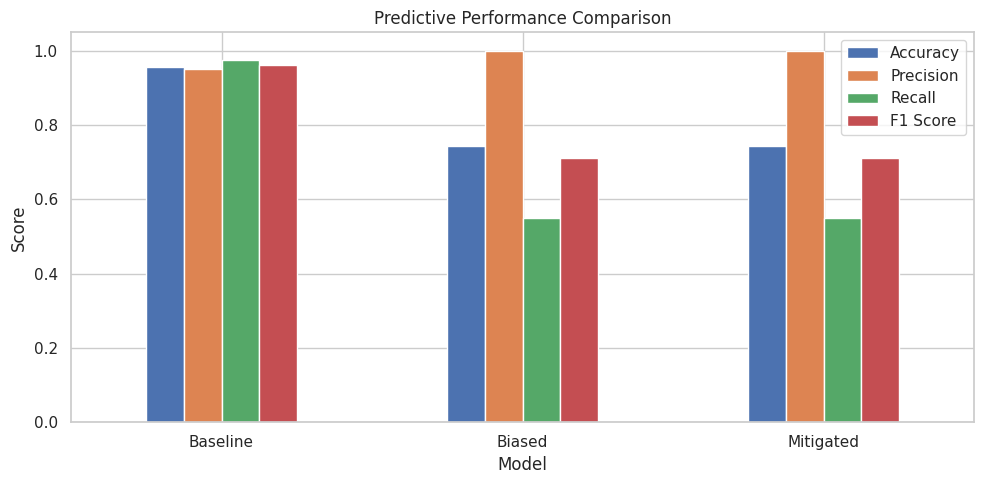

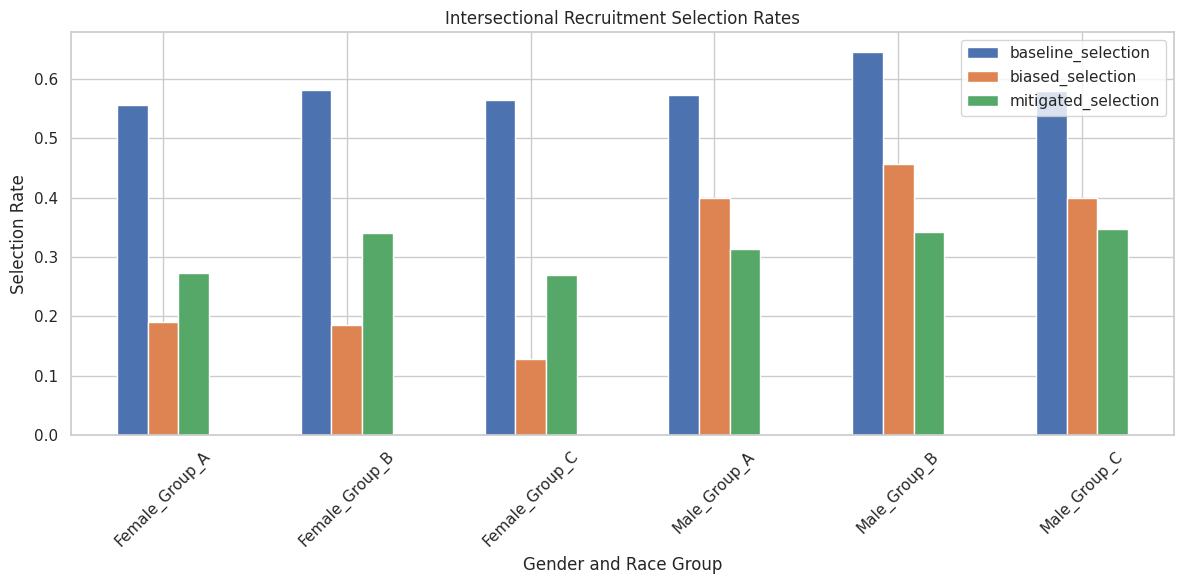

,Function,Application,Evidence
0,GOVERN,Assign accountability for recruitment AI,Documented roles and approval procedures
1,MAP,"Identify applicants, stakeholders and risks",Stakeholder and risk assessment
2,MEASURE,Evaluate fairness and model performance,Fairness metrics and audit results
3,MANAGE,Implement safeguards and monitor outcomes,Mitigation and monitoring plan


,Area,Framework,Governance Concern,Recommendation
0,Bias Auditing,NYC Local Law 144,An audit does not itself guarantee remediation,Document corrective actions
1,Transparency,NYC Local Law 144,Audit summaries may not explain individual out...,Provide understandable candidate information
2,Accountability,NIST AI RMF,Responsibility may be divided between vendors ...,Define ownership and escalation procedures
3,Continuous Monitoring,NIST AI RMF,Periodic audits may miss emerging problems,Monitor outcomes after deployment
4,Intersectional Fairness,Responsible AI practice,Small subgroup sizes can make estimates unstable,Report sample sizes and uncertainty



ALL FILES EXPORTED SUCCESSFULLY!
Experiment completed.


In [2]:

# ============================================================
# AI RECRUITMENT FAIRNESS & GOVERNANCE AUDIT
# Synthetic research experiment | Reproducible version
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

from fairlearn.reductions import ExponentiatedGradient, DemographicParity
from fairlearn.metrics import (
    demographic_parity_difference,
    demographic_parity_ratio,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    MetricFrame
)

np.random.seed(42)
sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. GENERATE SYNTHETIC DATASET
# ------------------------------------------------------------

n = 5000

data = pd.DataFrame({
    "applicant_id": range(1, n + 1),
    "gender_group": np.random.choice(
        ["Male", "Female"], n, p=[0.55, 0.45]
    ),
    "race_group": np.random.choice(
        ["Group_A", "Group_B", "Group_C"],
        n, p=[0.50, 0.30, 0.20]
    ),
    "education_level": np.random.choice(
        [1, 2, 3, 4], n, p=[0.15, 0.30, 0.40, 0.15]
    ),
    "years_experience": np.random.randint(0, 16, n),
    "skills_score": np.random.normal(70, 12, n).clip(0, 100),
    "assessment_score": np.random.normal(68, 14, n).clip(0, 100)
})

data["qualification_score"] = (
    0.20 * data["education_level"] / 4 * 100
    + 0.30 * data["years_experience"] / 15 * 100
    + 0.25 * data["skills_score"]
    + 0.25 * data["assessment_score"]
)

# Simulated objective qualification label
data["objectively_qualified"] = (
    data["qualification_score"] >= 60
).astype(int)

# Simulated unbiased historical decisions
data["baseline_decision"] = (
    data["qualification_score"] >= 65
).astype(int)

# Deliberately introduce gender-based historical bias
gender_penalty = np.where(
    data["gender_group"] == "Female", 8, 0
)

data["biased_historical_decision"] = (
    data["qualification_score"] - gender_penalty >= 65
).astype(int)

print("Dataset shape:", data.shape)
print(data.head())

# ------------------------------------------------------------
# 2. DATA QUALITY CHECK
# ------------------------------------------------------------

print("\nMissing values:")
print(data.isnull().sum())

print("\nGender distribution:")
print(data["gender_group"].value_counts())

print("\nObjective qualification rate:")
print(data["objectively_qualified"].mean())

print("\nHistorical selection rates:")
print(
    data.groupby("gender_group")[
        ["baseline_decision", "biased_historical_decision"]
    ].mean()
)

# ------------------------------------------------------------
# 3. SAME TRAIN-TEST SPLIT FOR ALL MODELS
# ------------------------------------------------------------

train_idx, test_idx = train_test_split(
    data.index,
    test_size=0.20,
    random_state=42,
    stratify=data["objectively_qualified"]
)

features = [
    "education_level",
    "years_experience",
    "skills_score",
    "assessment_score"
]

X = data[features]
X_biased = pd.get_dummies(
    data[features + ["gender_group"]],
    columns=["gender_group"],
    dtype=int
)

# Baseline model learns objective qualification labels
baseline_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

baseline_model.fit(
    X.loc[train_idx],
    data.loc[train_idx, "objectively_qualified"]
)

# Biased model learns deliberately biased historical decisions
biased_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

biased_model.fit(
    X_biased.loc[train_idx],
    data.loc[train_idx, "biased_historical_decision"]
)

test_data = data.loc[test_idx].copy()

test_data["baseline_prediction"] = baseline_model.predict(
    X.loc[test_idx]
)

test_data["biased_prediction"] = biased_model.predict(
    X_biased.loc[test_idx]
)

print("\nBaseline and biased models trained.")

# ------------------------------------------------------------
# 4. FAIRNESS MITIGATION
# ------------------------------------------------------------

# Protected attribute is supplied as sensitive_features,
# not included in the mitigation model's predictor features.

mitigation_model = ExponentiatedGradient(
    estimator=RandomForestClassifier(
        n_estimators=100,
        max_depth=6,
        random_state=42
    ),
    constraints=DemographicParity(),
    eps=0.02
)

mitigation_model.fit(
    X.loc[train_idx],
    data.loc[train_idx, "biased_historical_decision"],
    sensitive_features=data.loc[train_idx, "gender_group"]
)

test_data["mitigated_prediction"] = mitigation_model.predict(
    X.loc[test_idx]
).astype(int)

print("Fairness mitigation completed.")

# ------------------------------------------------------------
# 5. MODEL PERFORMANCE AND FAIRNESS SUMMARY
# ------------------------------------------------------------

models = [
    "baseline_prediction",
    "biased_prediction",
    "mitigated_prediction"
]

model_names = {
    "baseline_prediction": "Baseline",
    "biased_prediction": "Biased",
    "mitigated_prediction": "Mitigated"
}

y_true = test_data["objectively_qualified"]

summary = []

for model in models:
    y_pred = test_data[model]

    summary.append({
        "Model": model_names[model],
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Gender DP Difference": demographic_parity_difference(
            y_true,
            y_pred,
            sensitive_features=test_data["gender_group"]
        ),
        "Gender DP Ratio": demographic_parity_ratio(
            y_true,
            y_pred,
            sensitive_features=test_data["gender_group"]
        )
    })

model_summary = pd.DataFrame(summary)

print("\nMODEL PERFORMANCE SUMMARY")
display(model_summary.round(4))

# ------------------------------------------------------------
# 6. GENDER FAIRNESS AUDIT
# ------------------------------------------------------------

audit_results = []

for model in models:
    mf = MetricFrame(
        metrics={
            "Selection Rate": selection_rate,
            "True Positive Rate": true_positive_rate,
            "False Positive Rate": false_positive_rate
        },
        y_true=y_true,
        y_pred=test_data[model],
        sensitive_features=test_data["gender_group"]
    )

    for group, row in mf.by_group.iterrows():
        audit_results.append({
            "Model": model_names[model],
            "Gender": group,
            "Selection Rate": row["Selection Rate"],
            "True Positive Rate": row["True Positive Rate"],
            "False Positive Rate": row["False Positive Rate"]
        })

audit_results = pd.DataFrame(audit_results)

print("\nGENDER FAIRNESS RESULTS")
display(audit_results.round(4))

# ------------------------------------------------------------
# 7. INTERSECTIONAL FAIRNESS AUDIT
# ------------------------------------------------------------

test_data["intersection_group"] = (
    test_data["gender_group"] + "_" +
    test_data["race_group"]
)

intersection_audit = test_data.groupby(
    "intersection_group"
).agg(
    applicants=("applicant_id", "count"),
    qualified=("objectively_qualified", "sum"),
    baseline_selection=("baseline_prediction", "mean"),
    biased_selection=("biased_prediction", "mean"),
    mitigated_selection=("mitigated_prediction", "mean")
)

print("\nINTERSECTIONAL AUDIT")
display(intersection_audit.round(4))

# ------------------------------------------------------------
# 8. FALSE NEGATIVE RATE AUDIT
# ------------------------------------------------------------

def calculate_fnr(group, prediction_column):
    actual = group["objectively_qualified"]
    predicted = group[prediction_column]

    fn = ((actual == 1) & (predicted == 0)).sum()
    tp = ((actual == 1) & (predicted == 1)).sum()

    return fn / (fn + tp) if (fn + tp) > 0 else np.nan

fnr_results = []

for group_name, group in test_data.groupby("intersection_group"):
    for model in models:
        fnr_results.append({
            "Intersection": group_name,
            "Model": model_names[model],
            "False Negative Rate": calculate_fnr(group, model),
            "Applicants": len(group)
        })

fnr_audit = pd.DataFrame(fnr_results)

print("\nFALSE NEGATIVE RATE AUDIT")
display(fnr_audit.round(4))

# ------------------------------------------------------------
# 9. VISUALISATIONS
# ------------------------------------------------------------

selection_data = test_data.groupby("gender_group")[
    models
].mean()

selection_data.columns = [
    model_names[m] for m in models
]

selection_data.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Recruitment Selection Rates by Gender")
plt.ylabel("Selection Rate")
plt.xlabel("Gender")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

model_summary.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Predictive Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

intersection_audit[
    [
        "baseline_selection",
        "biased_selection",
        "mitigated_selection"
    ]
].plot(kind="bar", figsize=(12, 6))

plt.title("Intersectional Recruitment Selection Rates")
plt.ylabel("Selection Rate")
plt.xlabel("Gender and Race Group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. NIST AI RMF GOVERNANCE MAPPING
# ------------------------------------------------------------

nist_mapping = pd.DataFrame([
    {
        "Function": "GOVERN",
        "Application": "Assign accountability for recruitment AI",
        "Evidence": "Documented roles and approval procedures"
    },
    {
        "Function": "MAP",
        "Application": "Identify applicants, stakeholders and risks",
        "Evidence": "Stakeholder and risk assessment"
    },
    {
        "Function": "MEASURE",
        "Application": "Evaluate fairness and model performance",
        "Evidence": "Fairness metrics and audit results"
    },
    {
        "Function": "MANAGE",
        "Application": "Implement safeguards and monitor outcomes",
        "Evidence": "Mitigation and monitoring plan"
    }
])

display(nist_mapping)

# ------------------------------------------------------------
# 11. REGULATORY GOVERNANCE ANALYSIS
# ------------------------------------------------------------

policy_analysis = pd.DataFrame([
    {
        "Area": "Bias Auditing",
        "Framework": "NYC Local Law 144",
        "Governance Concern": "An audit does not itself guarantee remediation",
        "Recommendation": "Document corrective actions"
    },
    {
        "Area": "Transparency",
        "Framework": "NYC Local Law 144",
        "Governance Concern": "Audit summaries may not explain individual outcomes",
        "Recommendation": "Provide understandable candidate information"
    },
    {
        "Area": "Accountability",
        "Framework": "NIST AI RMF",
        "Governance Concern": "Responsibility may be divided between vendors and employers",
        "Recommendation": "Define ownership and escalation procedures"
    },
    {
        "Area": "Continuous Monitoring",
        "Framework": "NIST AI RMF",
        "Governance Concern": "Periodic audits may miss emerging problems",
        "Recommendation": "Monitor outcomes after deployment"
    },
    {
        "Area": "Intersectional Fairness",
        "Framework": "Responsible AI practice",
        "Governance Concern": "Small subgroup sizes can make estimates unstable",
        "Recommendation": "Report sample sizes and uncertainty"
    }
])

display(policy_analysis)

# ------------------------------------------------------------
# 12. EXPORT ALL RESULTS
# ------------------------------------------------------------

data.to_csv("synthetic_recruitment_dataset.csv", index=False)

test_data.to_csv("recruitment_test_predictions.csv", index=False)

model_summary.to_csv("model_comparison.csv", index=False)

audit_results.to_csv("gender_fairness_results.csv", index=False)

intersection_audit.to_csv("intersectional_audit.csv")

fnr_audit.to_csv("false_negative_audit.csv", index=False)

nist_mapping.to_csv("nist_governance_mapping.csv", index=False)

policy_analysis.to_csv(
    "regulatory_governance_analysis.csv", index=False
)

print("\nALL FILES EXPORTED SUCCESSFULLY!")
print("Experiment completed.")
